<h3 style="text-align: center;">Hello! Welcome to my notebook🩷


<img src="https://learnopencv.com/wp-content/uploads/2021/07/Conditional-GAN-in-PyTorch-and-TensorFlow.jpeg" alt="Image" width="600" height="100" style="display: block; margin: auto;">

### 📎Importing Libraries 

In [14]:
from tensorflow import keras
from tensorflow.keras.layers import *
from  tensorflow.keras.models import Model
from tensorflow.keras.datasets.cifar10 import load_data
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

### 📎Load the Data

In [15]:
(X_train,y_train),(_,_)=load_data()
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)


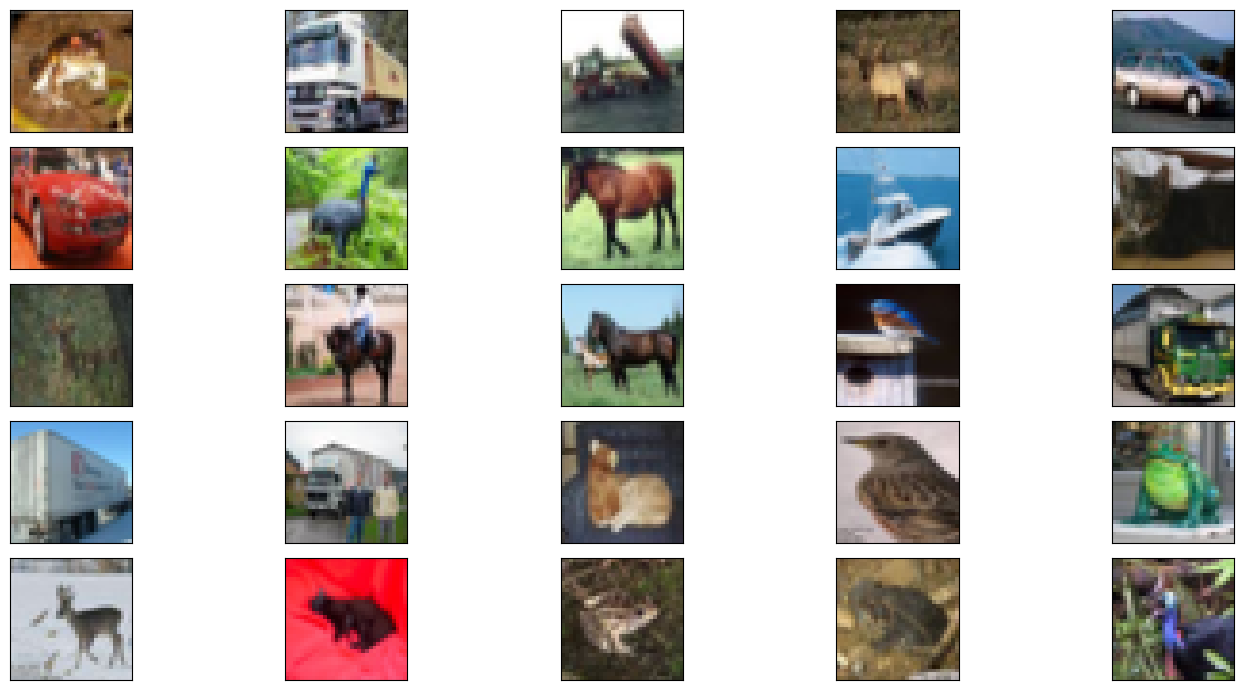

In [16]:
def plot_images(images, nrows=5, ncols=5, figsize=(15, 7)):

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, 
                             subplot_kw={'xticks': [], 'yticks': []})
    for i, ax in enumerate(axes.flat):
        if i < len(images): 
            ax.imshow(images[i])
        else:
            ax.axis('off')
    plt.tight_layout() 
    plt.show()

plot_images(X_train) 


In [17]:
unique_values = set(y_train.flatten())
print("Unique values in y_train:", unique_values)

Unique values in y_train: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9}


In [18]:
num_of_classes=len(unique_values)
num_of_classes

10

### 📎Normalization

In [19]:
X_train.max()

255

In [20]:
X_train=(X_train-127.5)/127.5

In [21]:
X_train.max()

1.0

In [22]:
X_train.min()

-1.0

> * I normalized Data to this Rnage **[-1,1]** not [0,1] , to fit **tanh fuunction** (in Generator) that produces outputs between −1,1.

# 📌Conditional Generative Adversarial Networks (CGANs)

> * **Conditional Generative Adversarial Networks (CGANs)** are an extension of GANs (Generative Adversarial Networks) that **enable the generation of images conditioned on certain attributes or classes**. This means that you can control the output of the generator by providing additional information (like class labels).

> **Generator**:
> > * Takes random noise as well as class labels as input and generates synthetic images.
> > * The generator learns to produce images that resemble real images from a specific class.

> **Discriminator**:

> > * Takes both real images and generated images along with their **corresponding class labels** as input.
> > * The discriminator learns to **distinguish between real and fake images** by evaluating both the images and the concatenated class labels. This allows it to assess whether an image is real or fake while considering the class information

> **Conditioning Information**:
> > * This could be class labels, attributes, or any auxiliary information that you want to condition the generation on.

### 📎Generator

In [23]:
def Generator(latent_dim, n_classes=num_of_classes):
    input_1=Input(shape=(1,))
    x1=Embedding(n_classes,50)(input_1) ##
    x1=Dense(8*8*1)(x1)
    x1=Reshape((8,8,1))(x1)


    input_2=Input(shape=(latent_dim,))
    x2=Dense(8*8*128)(input_2)
    x2=LeakyReLU(alpha=.2)(x2)
    x2=Reshape((8,8,128))(x2)
    x=Concatenate()([x2,x1])
    x=Conv2DTranspose(128, (4,4), strides=(2,2), padding='same')(x)
    x=LeakyReLU(alpha=.2)(x)
    x=Conv2DTranspose(128,(4,4),strides=(2,2),padding='same')(x)
    x=LeakyReLU(alpha=.2)(x)
    output= Conv2D(3, (8,8), activation='tanh', padding='same')(x)
    model=Model( [input_2,input_1],output)

    return model
  

In [24]:
latent_dim=100
generator=Generator(latent_dim,10)
generator.summary()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_4       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 8192)      │    827,392 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 50)     │        500 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 8192)      │          0 │ dense_5[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1, 64)     │      3,264 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 8, 8, 128) │          0 │ leaky_re_lu_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 8, 8, 1)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 8, 8, 129) │          0 │ reshape_4[0][0],  │
│ (Concatenate)       │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 16, 16,    │    264,320 │ concatenate_2[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 32, 32,    │    262,272 │ leaky_re_lu_6[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32, 3) │     24,579 │ leaky_re_lu_7[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,382,327 (5.27 MB)

 Trainable params: 1,382,327 (5.27 MB)

 Non-trainable params: 0 (0.00 B)

> **Generator Model Layers**
> > **Label Conversion**:
> > > * Class labels are converted to a 1D format for compatibility with the embedding layer.
> 
> > **Embedding Layer**:
> > > * Transforms 1D categorical labels into dense vector representations, capturing relationships between classes.
> 
> >  **Concatenation**: 
> > > * Combines the reshaped latent vector and embedded class label, allowing the model to generate class-specific images.
> 
> >**Model Structure**:
> 
> > > **Input Layers**: 
> > > > * Accepts both class label (after conversion) and latent vector inputs.
> > 
> > > **Dense Layers**:
> > > > * Transform and reshape inputs for processing.
> > 
> > >  **Reshape Layers**: 
> > > > * Prepare data for concatenation and convolution.
> > 
> > > **Transposed Convolutions**: 
> > > > * Upsample feature maps to generate output images.
> > 
> > > **Output Layer**: 
> > > > * Produces an RGB image (32x32x3) using a tanh activation function.

### 📎Discriminator

In [25]:
def Discriminator(n_classes=num_of_classes):
    input_1=Input(shape=(1,))
    x1=Embedding(n_classes,50)(input_1)
    x1=Dense(32*32)(x1)
    x1=Reshape((32,32,1))(x1)
    
    input_2=Input(shape=(32,32,3))
    x=Concatenate()([input_2,x1])
    x=Conv2D( 128,(3,3),strides=(2,2),padding='same',)(x)
    x=LeakyReLU(alpha=.2)(x)
    x=Conv2D(128,(3,3),strides=(2,2),padding='same')(x)
    x=LeakyReLU(alpha=.2)(x)
    
    flatten=Flatten()(x)
    x=Dropout(.4)(flatten)
    output=Dense(1,activation='sigmoid')(x)
    model=Model([input_2,input_1],output)
    opt = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

In [26]:
discriminator=Discriminator()
discriminator.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 1, 50)     │        500 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1, 1024)   │     52,224 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_5 (Reshape) │ (None, 32, 32, 1) │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 32, 32, 4) │          0 │ input_layer_7[0]… │
│ (Concatenate)       │                   │            │ reshape_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │      4,736 │ concatenate_3[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 16, 16,    │          0 │ conv2d_4[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 8, 8, 128) │    147,584 │ leaky_re_lu_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_9       │ (None, 8, 8, 128) │          0 │ conv2d_5[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 8192)      │          0 │ leaky_re_lu_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 8192)      │          0 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │      8,193 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 213,237 (832.96 KB)

 Trainable params: 213,237 (832.96 KB)

 Non-trainable params: 0 (0.00 B)

> **Discriminator Model Layers**
> 
> **Input Layer:** 
> > * Accepts class labels and real image inputs.
> 
> **Embedding Layer**: 
> > * Converts class labels into dense vectors to capture relationships.
> 
> **Dense Layer**:
> > * Expands the embedding output for integration with image data.
> 
> **Reshape Layer**:
> > * Adjusts the dense output into a spatial format compatible with image dimensions.
> 
> **Concatenate Layer**: 
> > * Merges the reshaped class embedding with the real image input.
> 
> **Convolutional Layers**:
> > * Two layers that reduce dimensions and extract features, using LeakyReLU for non-linearity.
> 
> **Flatten Layer**: 
> > * Converts 3D output into a 1D vector for fully connected layers.
> 
> **Dropout Layer**: 
> > * Reduces overfitting by randomly disabling a percentage of inputs during training.
> 
> **Output Layer**: 
> > * Produces a probability value indicating whether the input image is real (1) or fake (0).

### 📎CGAN (combine generator with discriminator)

In [27]:
def CGAN(generator,discriminator):
    discriminator.trainable=False
    vec,label=generator.input
    fake_image=generator.output
    output=discriminator([fake_image,label])
    model=Model([vec,label],output)
    opt = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    return model


In [28]:
GAN= CGAN(generator,discriminator)
GAN.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_4       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 8192)      │    827,392 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 50)     │        500 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 8192)      │          0 │ dense_5[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1, 64)     │      3,264 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 8, 8, 128) │          0 │ leaky_re_lu_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 8, 8, 1)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 8, 8, 129) │          0 │ reshape_4[0][0],  │
│ (Concatenate)       │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 16, 16,    │    264,320 │ concatenate_2[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 32, 32,    │    262,272 │ leaky_re_lu_6[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32, 3) │     24,579 │ leaky_re_lu_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_3        │ (None, 1)         │    213,237 │ conv2d_3[0][0],   │
│ (Functional)        │                   │            │ input_layer_4[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,595,564 (6.09 MB)

 Trainable params: 1,382,327 (5.27 MB)

 Non-trainable params: 213,237 (832.96 KB)

### 📎Generate Latent Vectors and Class Labels

In [29]:
def get_latent(n_sample):
    vec=np.random.randn(n_sample,latent_dim)
    label=np.random.randint(0,n_classes,n_sample)
    return  vec,label

### 📎Generate Fake Images and Corresponding Labels

In [30]:
def get_fake_data(n_sample):
    vec,label=get_latent(n_sample)
    fake_images=generator([vec,label])
    
    y=np.zeros([n_sample,1])
    return [fake_images,label],y

### 📎Yield Real Images and Corresponding Labels

In [31]:
def get_real_data(x_train,y_train,n_sample):
    data_size=len(x_train)
    index=[*range(data_size)]
    
    for idx in range(0,data_size,n_sample):
        real_images=x_train[idx:idx+n_sample]
        label=y_train[idx:idx+n_sample]
        y=np.ones([n_sample,1])
        yield [real_images,label],y

### 📎Generate GAN Inputs with Latent Vectors and Labels

In [32]:
def GAN_inputs(n_sample):
    vec,label=get_latent(n_sample)
    y=np.ones([n_sample,1])
    return [vec,label],y

### 📎Training the GAN: Discriminator and Generator Loss Calculation

In [33]:
# latent_dim = 100
n_classes = num_of_classes
n_sample = 128
epochs = 200  # Set to a higher number since early stopping will handle termination
batches = X_train.shape[0] // n_sample

# Early stopping parameters
patience = 10  # Number of epochs to wait for improvement
min_delta = 0.001  # Minimum improvement to count as progress
best_loss = float('inf')
wait = 0

for epoch in range(epochs):  
    real_data_generator = get_real_data(X_train, y_train, n_sample)
    
    total_d_loss_fake = 0
    total_d_loss_real = 0
    total_GAN_loss = 0
    
    for batch in range(batches):
        # Generate fake data
        [fake_images, label], y = get_fake_data(n_sample)
        d_loss_fake, _ = discriminator.train_on_batch([fake_images, label], y)

        # Get real data
        [real_images, label], y = next(real_data_generator)
        d_loss_real, _ = discriminator.train_on_batch([real_images, label], y)

        # Generate GAN inputs
        [vec, label], y = GAN_inputs(n_sample)
        GAN_loss = GAN.train_on_batch([vec, label], y)

        # Accumulate losses
        total_d_loss_fake += d_loss_fake
        total_d_loss_real += d_loss_real
        total_GAN_loss += GAN_loss
    
    # Calculate average loss per batch
    avg_GAN_loss = total_GAN_loss / batches
    avg_d_loss_fake = total_d_loss_fake / batches
    avg_d_loss_real = total_d_loss_real / batches
    
    print(f'Epoch {epoch} - d_loss_fake: {avg_d_loss_fake:.4f}, '
          f'd_loss_real: {avg_d_loss_real:.4f}, '
          f'GAN_loss: {avg_GAN_loss:.4f}')

    # Early stopping condition
    if best_loss - avg_GAN_loss > min_delta:
        best_loss = avg_GAN_loss
        wait = 0  # Reset patience counter if loss improves
    else:
        wait += 1
        if wait >= patience:
            print(f'Early stopping at epoch {epoch} due to no improvement in GAN loss')
            break


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/backend/tensorflow/trainer.py:83: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")
2026-01-17 21:42:09.420009: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Epoch 0 - d_loss_fake: 1.1485, d_loss_real: 1.1473, GAN_loss: 0.2833
Epoch 1 - d_loss_fake: 1.4372, d_loss_real: 1.4366, GAN_loss: 0.1439
Epoch 2 - d_loss_fake: 1.5180, d_loss_real: 1.5176, GAN_loss: 0.1181
Epoch 3 - d_loss_fake: 1.5644, d_loss_real: 1.5641, GAN_loss: 0.1053
Epoch 4 - d_loss_fake: 1.6004, d_loss_real: 1.6002, GAN_loss: 0.0968
Epoch 5 - d_loss_fake: 1.6291, d_loss_real: 1.6289, GAN_loss: 0.0906
Epoch 6 - d_loss_fake: 1.6515, d_loss_real: 1.6514, GAN_loss: 0.0860
Epoch 7 - d_loss_fake: 1.6696, d_loss_real: 1.6695, GAN_loss: 0.0824


KeyboardInterrupt: 

### 📎Generating and Visualizing Images with the GAN

In [ ]:
latent_points, labels = get_latent(100)

labels = np.asarray([x for _ in range(10) for x in range(10)])

X = generator.predict([latent_points, labels])  

#  from [-1, 1] to [0, 1]
X = (X + 1) / 2.0
X = (X * 255).astype(np.uint8)


In [ ]:
# Function to plot the generated images
def show_plot(examples, n):
    for i in range(n * n):
        plt.subplot(n, n, 1 + i)
        plt.axis('off')
        plt.imshow(examples[i, :, :, :])
    plt.show()

# Display the generated images
show_plot(X, 10)

### 📎Generate images using the generator for label 0


In [ ]:
latent_points, labels = get_latent(100)
labels = np.zeros(100) 

X = generator.predict([latent_points, labels]) 

# Scale pixel values from [-1, 1] to [0, 1]
X = (X + 1) / 2.0
X = (X * 255).astype(np.uint8)



show_plot(X, 10)


### Wish u luck
#### Esraa Meslam